In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [2]:
df=pd.read_csv("../../Data/Car Sell Dataset.csv")
df.sample(5)

,Brand,Model Name,Model Variant,Car Type,Transmission,Fuel Type,Year,Kilometers,Owner,State,Accidental,Price
36473,Mahindra,Bolero,W8,SUV,Manual,CNG,2008,30091,1st,Maharashtra,No,724185
104728,Maruti Suzuki,Baleno,V,Hatchback,Manual,CNG,2020,46351,1st,Rajasthan,No,270750
67555,Maruti Suzuki,Swift,Z,Sedan,Manual,Petrol,2016,148662,2nd,Maharashtra,No,456236
81611,Skoda,Rapid,Active,Sedan,Manual,Diesel,2013,24839,1st,Delhi,No,804650
117052,Maruti Suzuki,Alto,Base,Hatchback,Manual,CNG,2019,103580,1st,Maharashtra,No,1097250


In [3]:
cat_feat = ["Brand","Model Name","Model Variant","Car Type","Transmission","Fuel Type","Owner","State","Accidental"]
num_feat = ["Year","Kilometers"]

features=cat_feat+num_feat

In [5]:
X = df[features]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)
print("Train Data",len(X_train))
print("Test Data",len(X_test))

Train Data 112723
Test Data 28181


In [6]:
cat_transformer=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("encoder",OneHotEncoder(handle_unknown="ignore"))
    ]
)

num_transformer=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median"))
    ]
)

preprocessor=ColumnTransformer(
    transformers=[
        ("categorical",cat_transformer,cat_feat),
        ("numerical",num_transformer,num_feat)
    ]
)

In [7]:
model=RandomForestRegressor(n_estimators=200,max_features=0.8,min_samples_leaf=2,random_state=42,n_jobs=-1)

pipeline=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",model)
    ]
)

In [8]:
pipeline.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [9]:
y_pred=pipeline.predict(X_test)

In [10]:
mae=mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

In [11]:
print(mae)
print(rmse)
print(r2)

304303.15648974257
374803.9108198124
0.2850450702762912


In [12]:
y.describe()

count    1.409040e+05
mean     7.617872e+05
std      4.438578e+05
min      5.005500e+04
25%      4.116420e+05
50%      6.828030e+05
75%      1.034178e+06
max      2.744280e+06
Name: Price, dtype: float64

In [13]:
y.quantile([0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

0.01     124146.00
0.25     411642.00
0.50     682803.00
0.75    1034178.25
0.90    1389850.00
0.95    1617000.00
0.99    2009700.00
Name: Price, dtype: float64

In [14]:
X.isnull().sum()

Brand            0
Model Name       0
Model Variant    0
Car Type         0
Transmission     0
Fuel Type        0
Owner            0
State            0
Accidental       0
Year             0
Kilometers       0
dtype: int64

In [16]:
df[["Year", "Kilometers", "Price"]].corr()

,Year,Kilometers,Price
Year,1.000000,0.003108,0.404462
Kilometers,0.003108,1.000000,-0.214301
Price,0.404462,-0.214301,1.000000


In [ ]:
df.groupby("Brand")["Price"].agg(["count", "mean", "median"]).sort_values("mean", ascending=False).round(2)

,count,mean,median
Brand,,,
MG,1492,1024061.36,979967.5
Kia,2146,1002335.19,970200.0
Tata,8825,902304.86,848457.0
Renault,3024,884928.17,825000.0
Range Rover,906,845635.10,762300.0
Jaguar,884,791583.30,726023.5
Toyota,10483,790569.33,694260.0
Skoda,1537,774065.82,689700.0
Hyundai,22090,762921.30,679945.0


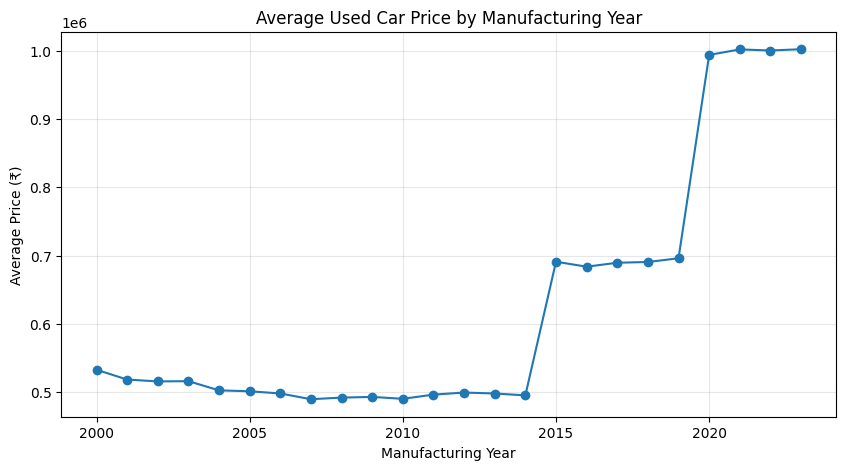

In [18]:
import matplotlib.pyplot as plt
df.groupby("Year")["Price"].mean().plot(
    figsize=(10, 5),
    marker="o",
    title="Average Used Car Price by Manufacturing Year"
)

plt.xlabel("Manufacturing Year")
plt.ylabel("Average Price (₹)")
plt.grid(alpha=0.3)
plt.show()

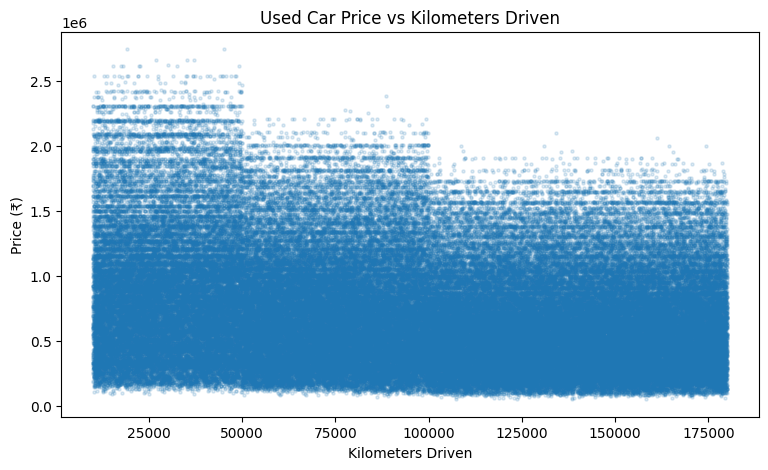

In [19]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Kilometers"],
    df["Price"],
    alpha=0.15,
    s=5
)

plt.xlabel("Kilometers Driven")
plt.ylabel("Price (₹)")
plt.title("Used Car Price vs Kilometers Driven")
plt.show()

In [20]:
year_analysis = df.groupby("Year").agg(
    Listings=("Price", "count"),
    Average_Price=("Price", "mean"),
    Median_Price=("Price", "median")
).round(2)

print(year_analysis.to_string())

      Listings  Average_Price  Median_Price
Year                                       
2000       732      532649.58      511040.0
2001       720      518309.17      493448.5
2002       804      515576.70      479160.0
2003       836      515957.89      493448.5
2004       866      502479.91      461191.0
2005      1319      501112.77      476437.0
2006      1453      497933.98      471673.0
2007      1504      489497.17      459814.5
2008      2469      491881.16      473715.0
2009      2964      492860.35      459800.0
2010      3606      490097.63      464526.0
2011      4264      496242.75      467277.0
2012      5050      499261.39      470720.0
2013      5708      497877.23      469724.0
2014      5706      495116.05      475238.0
2015      7363      690921.56      667012.0
2016      7797      683629.51      658350.0
2017      9687      689401.26      667012.0
2018      9479      690519.29      667012.0
2019     12367      695949.75      672043.0
2020     14608      993825.23   

In [21]:
year_car_type = pd.pivot_table(
    df,
    index="Year",
    columns="Car Type",
    values="Price",
    aggfunc="mean"
)

print(year_car_type.round(0).to_string())

Car Type  Hatchback     Luxury        MPV        SUV     Sedan
Year                                                          
2000       548530.0   523992.0        NaN   524689.0  458440.0
2001       527922.0   554744.0        NaN   515321.0  471180.0
2002       516980.0   518349.0        NaN   518099.0  503777.0
2003       506132.0   576056.0        NaN   535136.0  509807.0
2004       491787.0   499215.0   503810.0   541756.0  469058.0
2005       506130.0   535656.0   507219.0   515639.0  484046.0
2006       512146.0   439280.0   475230.0   534697.0  480798.0
2007       484655.0   445227.0   502360.0   504265.0  487343.0
2008       498770.0   613266.0   494578.0   499798.0  479877.0
2009       493981.0   490122.0   498968.0   514519.0  484293.0
2010       499072.0   531201.0   459685.0   526070.0  472729.0
2011       498593.0   603350.0   479193.0   532977.0  476174.0
2012       509345.0   585055.0   507156.0   519644.0  469597.0
2013       492961.0   544166.0   517139.0   519912.0  4

In [22]:
for year in [2014, 2015, 2019, 2020]:
    print(f"\n--- Year {year} ---")

    print(
        df[df["Year"] == year]
        .groupby("Brand")["Price"]
        .agg(["count", "mean", "median"])
        .sort_values("count", ascending=False)
        .head(10)
        .round(0)
    )


--- Year 2014 ---
               count      mean    median
Brand                                   
Maruti Suzuki   2252  495069.0  479160.0
Honda            748  478214.0  455202.0
Hyundai          717  493076.0  479160.0
Mahindra         503  529716.0  510979.0
Toyota           429  506228.0  479160.0
Ford             334  497718.0  461191.0
Nissan           166  485088.0  456308.0
Volkswagen       138  472189.0  444166.0
Audi              89  468776.0  427527.0
Chevrolet         81  449354.0  408375.0

--- Year 2015 ---
               count      mean    median
Brand                                   
Maruti Suzuki   2965  686168.0  663201.0
Hyundai         1045  687478.0  665000.0
Honda            782  681888.0  659087.0
Mahindra         775  730758.0  723173.0
Ford             530  687350.0  659264.0
Toyota           428  686018.0  658350.0
Nissan           195  665704.0  625432.0
Renault          157  714570.0  716788.0
Volkswagen       147  688403.0  693000.0
Chevrolet         7

In [23]:
comparison = df[
    (df["Brand"] == "Maruti Suzuki") &
    (df["Model Name"] == "Swift") &
    (df["Year"].isin([2014, 2015, 2019, 2020, 2021, 2022, 2023]))
]

print(
    comparison[
        ["Brand", "Model Name", "Model Variant",
         "Year", "Kilometers", "Price"]
    ].sort_values("Year").head(30).to_string(index=False)
)

        Brand Model Name Model Variant  Year  Kilometers  Price
Maruti Suzuki      Swift          Base  2014      168107  96989
Maruti Suzuki      Swift             Z  2014       23209 432800
Maruti Suzuki      Swift          Base  2014      173161 331783
Maruti Suzuki      Swift             V  2014       23132 708092
Maruti Suzuki      Swift            ZX  2014       31388 364930
Maruti Suzuki      Swift            ZX  2014      131052 737427
Maruti Suzuki      Swift            ZX  2014      144407 405584
Maruti Suzuki      Swift             L  2014       18521 850588
Maruti Suzuki      Swift          Base  2014      141376 129318
Maruti Suzuki      Swift             V  2014       51361 107274
Maruti Suzuki      Swift             L  2014       62010 528034
Maruti Suzuki      Swift             Z  2014      163795 447184
Maruti Suzuki      Swift            ZX  2014      116131 491618
Maruti Suzuki      Swift             V  2014      108550 303468
Maruti Suzuki      Swift            ZX  

<Figure size 1200x600 with 0 Axes>

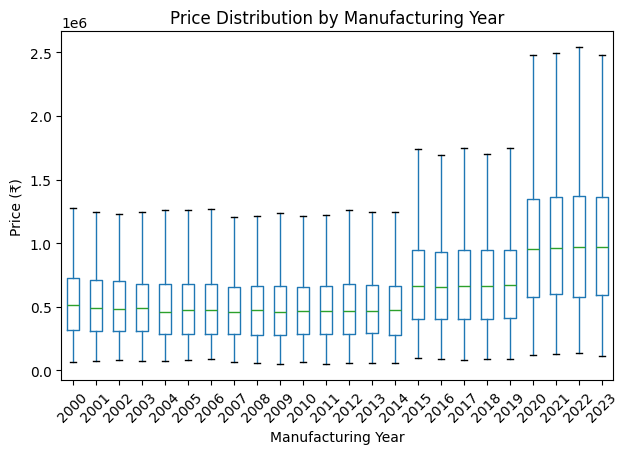

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

df.boxplot(
    column="Price",
    by="Year",
    grid=False,
    showfliers=False
)

plt.title("Price Distribution by Manufacturing Year")
plt.suptitle("")
plt.xlabel("Manufacturing Year")
plt.ylabel("Price (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
for year in [2014, 2015, 2019, 2020]:
    subset = df[df["Year"] == year]

    print(f"\nYear: {year}")
    print("Unique prices:", subset["Price"].nunique())
    print("Most common prices:")
    print(subset["Price"].value_counts().head(10))


Year: 2014
Unique prices: 2072
Most common prices:
Price
758670    29
638880    27
569002    24
279510    23
606936    22
670824    22
359370    22
159720    21
646593    21
798600    21
Name: count, dtype: int64

Year: 2015
Unique prices: 2196
Most common prices:
Price
1097250    44
658350     38
877800     37
438900     36
808500     34
219450     32
603487     32
727650     30
965580     28
1155000    28
Name: count, dtype: int64

Year: 2019
Unique prices: 2898
Most common prices:
Price
1097250    65
231000     56
970200     54
924000     54
965580     50
1212750    48
1152112    48
404250     47
1091475    47
462000     46
Name: count, dtype: int64

Year: 2020
Unique prices: 3120
Most common prices:
Price
1039500    85
1732500    80
346500     73
1567500    72
693000     71
1254000    69
1386000    66
1299375    64
330000     63
1645875    59
Name: count, dtype: int64


In [26]:
model_analysis = (
    df.groupby(["Brand", "Model Name", "Year"])["Price"]
    .agg(["count", "mean", "median", "min", "max", "std"])
    .reset_index()
)

print(
    model_analysis[
        (model_analysis["Model Name"] == "Swift") &
        (model_analysis["Brand"] == "Maruti Suzuki")
    ].to_string(index=False)
)

        Brand Model Name  Year  count          mean   median    min     max           std
Maruti Suzuki      Swift  2005    316 484143.015823 452925.5  82065 1365606 251325.008412
Maruti Suzuki      Swift  2006    334 487051.293413 465637.5  89261 1117314 245611.949787
Maruti Suzuki      Swift  2007    303 496629.772277 466393.0  93109 1194905 255001.160803
Maruti Suzuki      Swift  2008    313 485990.412141 455202.0 101838 1206975 241735.313030
Maruti Suzuki      Swift  2009    306 489253.189542 455202.0  79575 1365606 269982.003705
Maruti Suzuki      Swift  2010    296 472138.756757 443265.0  87951 1179387 251114.627479
Maruti Suzuki      Swift  2011    327 484343.339450 462314.0  50055 1365606 269039.922401
Maruti Suzuki      Swift  2012    322 483042.273292 464059.0  64801 1080070 239225.131529
Maruti Suzuki      Swift  2013    335 490907.862687 482790.0  90464 1327672 251556.525369
Maruti Suzuki      Swift  2014    285 456450.480702 432800.0  87509 1213872 242686.031313
Maruti Suz

In [27]:
variation = (
    df.groupby(["Brand", "Model Name", "Year"])["Price"]
    .agg(["count", "mean", "std", "min", "max"])
    .reset_index()
)

variation["CV"] = variation["std"] / variation["mean"]

print(
    variation[variation["count"] >= 20]
    .sort_values("CV", ascending=False)
    .head(20)
    .round(2)
)

           Brand       Model Name  Year  count        mean        std     min  \
116          BMW               X1  2014     20   524869.35  367518.70   95228   
751        Skoda            Rapid  2011     32   414373.41  279933.57  114007   
671  Range Rover           Evoque  2018     22   674670.18  440652.61  181046   
165    Chevrolet            Spark  2010     20   487475.15  313175.34   68881   
142    Chevrolet             Beat  2013     21   403596.14  255260.66  102279   
18          Audi               A6  2014     22   365449.23  230727.68   91428   
667  Range Rover           Evoque  2014     24   504316.46  310899.74  113800   
34          Audi               Q3  2018     23   632596.13  388222.10  167706   
874   Volkswagen             Polo  2011     68   496848.16  302522.84   88171   
451     Mahindra          Scorpio  2009     88   516292.81  313141.96   89877   
752        Skoda            Rapid  2012     30   387990.40  235213.66   88388   
876   Volkswagen            

In [28]:
print(
    df.groupby("Accidental")["Price"]
    .agg(["count", "mean", "median"])
)

print(
    df.groupby("Owner")["Price"]
    .agg(["count", "mean", "median"])
)

print(
    df.groupby("Transmission")["Price"]
    .agg(["count", "mean", "median"])
)

             count           mean    median
Accidental                                 
No          129639  780924.153357  703395.0
Yes          11265  541556.469596  484621.0
       count           mean    median
Owner                                
1st    75429  878378.876559  820507.0
2nd    56492  665938.249345  612626.0
3rd+    8983  385554.501280  374343.0
               count           mean    median
Transmission                                 
Automatic      21111  823459.687935  740643.0
Manual        119793  750918.688696  673312.0


In [29]:
variant_analysis = (
    df.groupby(
        ["Brand", "Model Name", "Model Variant", "Year"]
    )["Price"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reset_index()
)

variant_analysis["CV"] = (
    variant_analysis["std"] / variant_analysis["mean"]
)

print(
    variant_analysis[
        variant_analysis["count"] >= 15
    ]
    .sort_values("CV", ascending=False)
    .head(20)
    .round(2)
    .to_string(index=False)
)


        Brand Model Name Model Variant  Year  count       mean   median       std    min     max   CV
         Ford       Figo      Titanium  2010     17  314529.76 264017.0 232672.15  98900  950061 0.74
       Toyota     Innova             G  2010     22  378306.55 321935.5 279030.50  97926 1052700 0.74
       Toyota     Innova             V  2007     22  407990.09 278711.0 300342.42 113800 1210000 0.74
       Toyota     Innova            VX  2010     17  443431.41 319440.0 323252.78 132008 1171280 0.73
        Honda       City             V  2006     15  429161.47 348424.0 312741.85  86766 1092025 0.73
      Renault       Kwid           RXZ  2015     25  594012.56 404250.0 432000.09 131670 1540000 0.73
      Renault       Kwid           RXT  2015     18  579021.44 465832.5 414385.22 152460 1540000 0.72
  Range Rover      Velar            SE  2019     20  740892.75 614918.5 528473.30 184476 1863400 0.71
        Honda       City             S  2004     18  451178.17 367936.0 315112.13 

In [30]:
swift = df[
    (df["Brand"] == "Maruti Suzuki") &
    (df["Model Name"] == "Swift")
]

print(
    swift.groupby(["Year", "Model Variant"])["Price"]
    .agg(["count", "mean", "median", "std"])
    .round(0)
    .to_string()
)

                    count       mean     median       std
Year Model Variant                                       
2005 Base              67   461803.0   455202.0  220564.0
     L                 67   431461.0   400577.0  208802.0
     V                 55   472026.0   440028.0  253740.0
     Z                 62   499381.0   477215.0  251475.0
     ZX                65   557191.0   492512.0  303247.0
2006 Base              80   495808.0   470030.0  236150.0
     L                 64   464292.0   386232.0  234906.0
     V                 60   462832.0   433511.0  270870.0
     Z                 66   511773.0   481696.0  242305.0
     ZX                64   496076.0   495342.0  250117.0
2007 Base              66   431066.0   450029.0  197270.0
     L                 50   440899.0   406844.0  240559.0
     V                 47   495809.0   519321.0  230601.0
     Z                 65   551874.0   543138.0  280634.0
     ZX                75   544116.0   496584.0  284264.0
2008 Base     

In [31]:
sample = df[
    (df["Brand"] == "Maruti Suzuki") &
    (df["Model Name"] == "Swift") &
    (df["Model Variant"] == "Base") &
    (df["Year"] == 2014)
]

print("Records:", len(sample))

print("\nPrice statistics:")
print(sample["Price"].describe())

print("\nPrice by accidental history:")
print(
    sample.groupby("Accidental")["Price"]
    .agg(["count", "mean", "median", "std"])
)

print("\nPrice by owner:")
print(
    sample.groupby("Owner")["Price"]
    .agg(["count", "mean", "median", "std"])
)

print("\nPrice correlations:")
print(
    sample[["Price", "Kilometers"]].corr(method="spearman")
)

Records: 54

Price statistics:
count    5.400000e+01
mean     4.230316e+05
std      2.391636e+05
min      9.698900e+04
25%      2.303892e+05
50%      3.684110e+05
75%      5.847790e+05
max      1.000065e+06
Name: Price, dtype: float64

Price by accidental history:
            count       mean    median            std
Accidental                                           
No             50  434455.42  417085.5  243678.466113
Yes             4  280234.25  325484.5  106282.249008

Price by owner:
       count           mean    median            std
Owner                                               
1st       10  573803.700000  500941.5  296765.420896
2nd       31  396516.419355  341401.0  193534.180264
3rd+      13  370281.692308  337845.0  262991.739922

Price correlations:
               Price  Kilometers
Price       1.000000   -0.238663
Kilometers -0.238663    1.000000


In [32]:
df["Car_Age"] = 2023 - df["Year"]

df["KM_Per_Year"] = (
    df["Kilometers"] / df["Car_Age"].replace(0, 1)
)

df["Price"] = df["Price"].astype(float)

print(
    df[["Year", "Car_Age", "Kilometers", "KM_Per_Year", "Price"]]
    .head()
)

   Year  Car_Age  Kilometers   KM_Per_Year     Price
0  2017        6      164654  27442.333333  547253.0
1  2018        5       41351   8270.200000  512050.0
2  2002       21      119090   5670.952381  678923.0
3  2013       10       19979   1997.900000  522500.0
4  2011       12      130591  10882.583333  401182.0


In [33]:
from sklearn.ensemble import ExtraTreesRegressor,HistGradientBoostingRegressor
from sklearn.base import clone

In [36]:
categorical_features = [
    "Brand", "Model Name", "Model Variant",
    "Car Type", "Transmission", "Fuel Type",
    "Owner", "State", "Accidental"
]

numerical_features = [
    "Car_Age", "Kilometers", "KM_Per_Year"
]

features = categorical_features + numerical_features

X = df[features]
y = np.log1p(df["Price"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]), categorical_features),

        ("num", SimpleImputer(strategy="median"), numerical_features)
    ],
    sparse_threshold=0
)

In [37]:
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    ),

    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

results = []

for name, estimator in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)

    predictions = np.expm1(pipeline.predict(X_test))
    actual = np.expm1(y_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2": r2_score(actual, predictions)
    })

results_df = pd.DataFrame(results).sort_values("MAE")

print(results_df.to_string(index=False))

                 Model           MAE          RMSE       R2
Hist Gradient Boosting 304186.283175 375760.206221 0.281392
         Random Forest 310952.917922 387059.979541 0.237523
           Extra Trees 315462.859159 394595.230584 0.207546


In [38]:
from catboost import CatBoostRegressor

X_cat = df[features].copy()
y_cat = df["Price"].copy()

for col in categorical_features:
    X_cat[col] = X_cat[col].fillna("Unknown").astype(str)

for col in numerical_features:
    X_cat[col] = X_cat[col].fillna(X_cat[col].median())

In [39]:
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(X_cat,y_cat,test_size=0.20,random_state=42)

In [40]:
cat_model=CatBoostRegressor(iterations=1000,depth=8,learning_rate=0.05,loss_function="RMSE",eval_metric="MAE",verbose=200,random_seed=42,allow_writing_files=False)

cat_model.fit(X_train_cat,y_train_cat,cat_features=categorical_features,eval_set=(X_test_cat,y_test_cat),early_stopping_rounds=100)

0:	learn: 353275.1344572	test: 351892.2227704	best: 351892.2227704 (0)	total: 1.46s	remaining: 24m 17s
200:	learn: 296212.5531473	test: 297263.1052464	best: 297229.9954291 (134)	total: 36.9s	remaining: 2m 26s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 297229.9954
bestIteration = 134

Shrink model to first 135 iterations.


CatBoostRegressor(allow_writing_files=False, depth=8, eval_metric='MAE', iterations=1000, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=200)

In [41]:
cat_pred = cat_model.predict(X_test_cat)

print("\nCATBOOST PERFORMANCE")
print("MAE:", mean_absolute_error(y_test_cat, cat_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test_cat, cat_pred)))
print("R2:", r2_score(y_test_cat, cat_pred))


CATBOOST PERFORMANCE
MAE: 297229.9954301357
RMSE: 362227.6380423953
R2: 0.33221969612467894


      Feature  Importance
      Car_Age   49.744183
   Kilometers   14.220606
   Accidental   11.267127
        Owner    6.728348
        State    6.697254
     Car Type    3.308322
 Transmission    2.404851
Model Variant    2.198381
    Fuel Type    2.060898
   Model Name    0.579453
        Brand    0.409841
  KM_Per_Year    0.380737


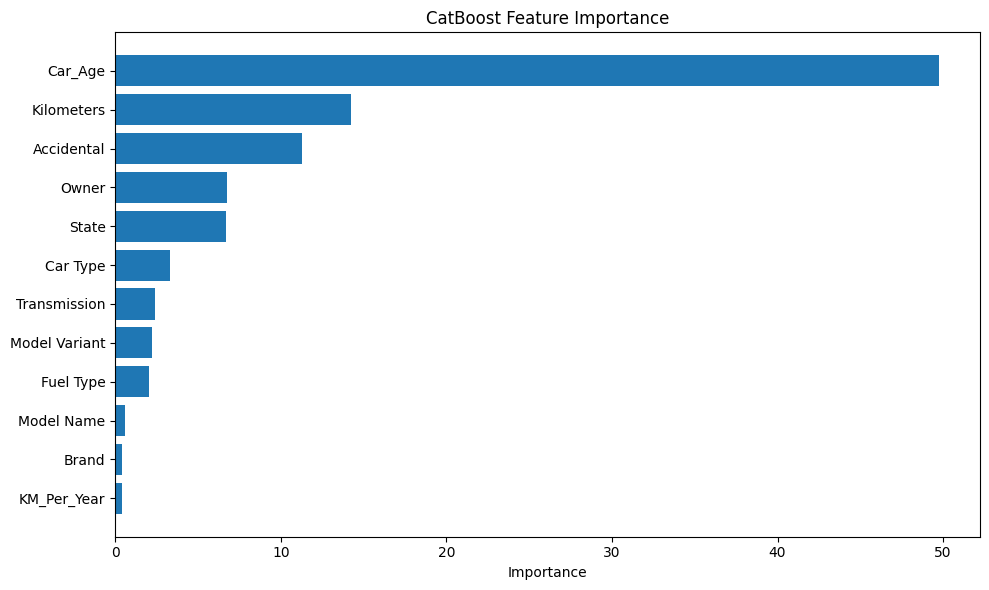

In [42]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": cat_model.get_feature_importance()
})

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

print(feature_importance.to_string(index=False))

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.title("CatBoost Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [43]:
X_train, X_temp, y_train, y_temp = train_test_split(X_cat, y_cat,test_size=0.30,random_state=42)

In [44]:
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp,test_size=0.50,random_state=42)

In [46]:
cat_model = CatBoostRegressor(iterations=1000,depth=8,learning_rate=0.05,loss_function="RMSE",eval_metric="MAE",verbose=200,random_seed=42,allow_writing_files=False)

In [47]:
cat_model.fit(X_train,y_train,cat_features=categorical_features,eval_set=(X_val, y_val),early_stopping_rounds=100)

0:	learn: 353154.2348828	test: 352685.9578367	best: 352685.9578367 (0)	total: 568ms	remaining: 9m 27s
200:	learn: 296462.6752211	test: 297735.1016619	best: 297718.2272741 (184)	total: 33.1s	remaining: 2m 11s
400:	learn: 294322.7346863	test: 297736.1563123	best: 297698.2912907 (325)	total: 1m 4s	remaining: 1m 35s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 297698.2913
bestIteration = 325

Shrink model to first 326 iterations.


CatBoostRegressor(allow_writing_files=False, depth=8, eval_metric='MAE', iterations=1000, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=200)

In [48]:
test_predictions = cat_model.predict(X_test)

print("\nFINAL TEST PERFORMANCE")

print("MAE:", mean_absolute_error(y_test, test_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, test_predictions)))
print("R2:", r2_score(y_test, test_predictions))


FINAL TEST PERFORMANCE
MAE: 296544.3545931178
RMSE: 361242.15471746813
R2: 0.3370955377518581


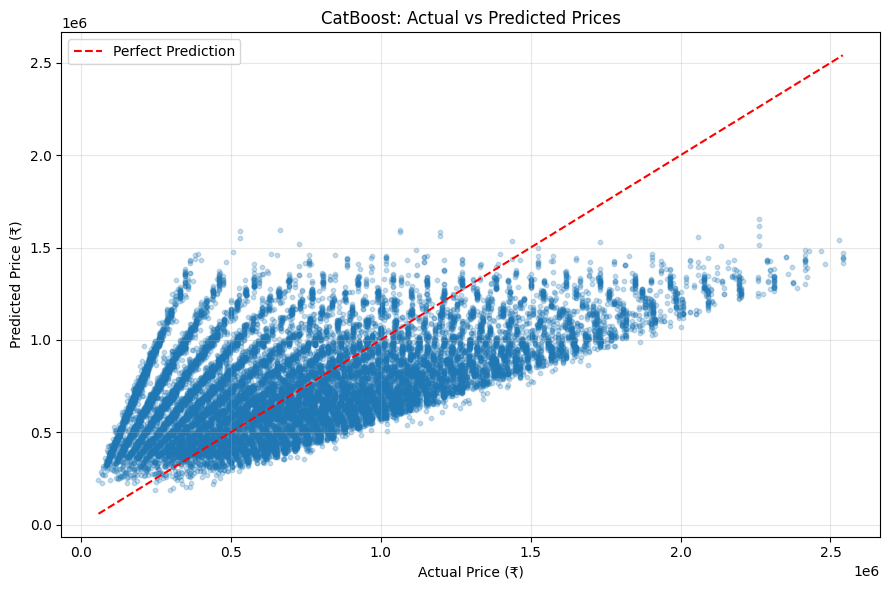

In [49]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.25,
    s=10
)

min_val = min(y_test.min(), test_predictions.min())
max_val = max(y_test.max(), test_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.title("CatBoost: Actual vs Predicted Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

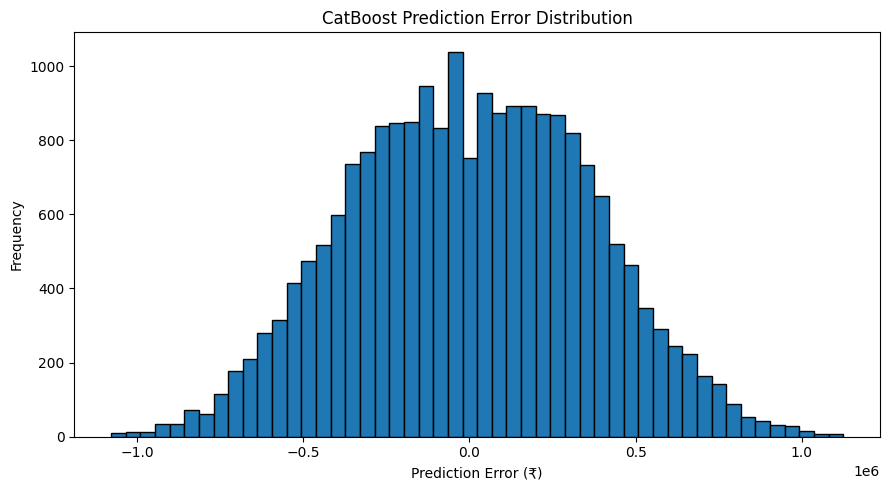

In [50]:
errors = y_test - test_predictions

plt.figure(figsize=(9, 5))

plt.hist(errors, bins=50, edgecolor="black")

plt.xlabel("Prediction Error (₹)")
plt.ylabel("Frequency")
plt.title("CatBoost Prediction Error Distribution")

plt.tight_layout()
plt.show()

In [51]:
error_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": test_predictions
})

error_analysis["Absolute_Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
).abs()

error_analysis["Price_Range"] = pd.cut(
    error_analysis["Actual"],
    bins=[0, 300000, 500000, 800000, 1200000, float("inf")],
    labels=[
        "Below 3L",
        "3L-5L",
        "5L-8L",
        "8L-12L",
        "Above 12L"
    ]
)

print(
    error_analysis.groupby(
        "Price_Range", observed=False
    ).agg(
        Cars=("Actual", "count"),
        MAE=("Absolute_Error", "mean"),
        Average_Actual=("Actual", "mean"),
        Average_Predicted=("Predicted", "mean")
    ).round(2)
)

             Cars        MAE  Average_Actual  Average_Predicted
Price_Range                                                    
Below 3L     3048  377066.71       212640.70          589513.68
3L-5L        3971  289010.24       397778.40          671220.50
5L-8L        5420  191662.33       647021.14          702372.62
8L-12L       5147  233396.12       979117.71          810228.30
Above 12L    3550  487521.92      1516621.22         1031301.92


In [52]:
cat_mae_model = CatBoostRegressor(iterations=1500,depth=8,learning_rate=0.03,loss_function="MAE",eval_metric="MAE",l2_leaf_reg=5,verbose=200,random_seed=42,allow_writing_files=False)

cat_mae_model.fit(X_train,y_train,cat_features=categorical_features,eval_set=(X_val, y_val),early_stopping_rounds=150)

0:	learn: 350039.8652005	test: 349071.4561238	best: 349071.4561238 (0)	total: 481ms	remaining: 12m 1s
200:	learn: 296446.1128961	test: 298148.6926383	best: 298136.3014186 (188)	total: 33.2s	remaining: 3m 34s
400:	learn: 294400.7712052	test: 298162.3278421	best: 298120.6312758 (297)	total: 1m 4s	remaining: 2m 56s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 298120.6313
bestIteration = 297

Shrink model to first 298 iterations.


CatBoostRegressor(allow_writing_files=False, depth=8, eval_metric='MAE', iterations=1500, l2_leaf_reg=5, learning_rate=0.03, loss_function='MAE', random_seed=42, verbose=200)

In [ ]:
mae_predictions = cat_mae_model.predict(X_test)

print("\nCATBOOST MAE LOSS PERFORMANCE")
print("MAE:",mean_absolute_error(y_test, mae_predictions))
print("RMSE:",np.sqrt(mean_squared_error(y_test, mae_predictions)))
print("R2:",r2_score(y_test, mae_predictions))


CATBOOST MAE LOSS PERFORMANCE
MAE: 296977.4734101042
RMSE: 362184.83097182127
R2: 0.3336312706721719


In [54]:
depth_results = []
depth_models = {}

for depth in [6, 8, 10]:

    print(f"\nTraining CatBoost with depth={depth}")

    model = CatBoostRegressor(
        iterations=1500,
        depth=depth,
        learning_rate=0.05,
        loss_function="RMSE",
        eval_metric="MAE",
        l2_leaf_reg=3,
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features,
        eval_set=(X_val, y_val),
        early_stopping_rounds=100,
        verbose=False
    )

    val_predictions = model.predict(X_val)

    val_mae = mean_absolute_error(
        y_val, val_predictions
    )

    depth_results.append({
        "Depth": depth,
        "Best Iteration": model.best_iteration_,
        "Validation MAE": val_mae
    })

    depth_models[depth] = model

depth_df = pd.DataFrame(depth_results)

print("\nDEPTH COMPARISON")
print(depth_df.sort_values("Validation MAE").to_string(index=False))



Training CatBoost with depth=6

Training CatBoost with depth=8

Training CatBoost with depth=10

DEPTH COMPARISON
 Depth  Best Iteration  Validation MAE
     6             344   297649.522684
     8             325   297698.291292
    10             202   297704.908115


In [55]:
learning_results = []
learning_models = {}

for lr in [0.03, 0.05, 0.08]:

    print(f"Training with learning_rate={lr}")

    model = CatBoostRegressor(
        iterations=1500,
        depth=6,
        learning_rate=lr,
        loss_function="RMSE",
        eval_metric="MAE",
        l2_leaf_reg=3,
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features,
        eval_set=(X_val, y_val),
        early_stopping_rounds=100,
        verbose=False
    )

    val_predictions = model.predict(X_val)

    val_mae = mean_absolute_error(
        y_val, val_predictions
    )

    learning_results.append({
        "Learning Rate": lr,
        "Best Iteration": model.best_iteration_,
        "Validation MAE": val_mae
    })

    learning_models[lr] = model

learning_df = pd.DataFrame(learning_results)

print("\nLEARNING RATE COMPARISON")
print(
    learning_df.sort_values("Validation MAE")
    .to_string(index=False)
)

Training with learning_rate=0.03
Training with learning_rate=0.05
Training with learning_rate=0.08

LEARNING RATE COMPARISON
 Learning Rate  Best Iteration  Validation MAE
          0.08             227   297643.913193
          0.05             344   297649.522684
          0.03             302   297688.802743


In [56]:
regularization_results = []
regularization_models = {}

for reg in [3, 5, 7, 10]:

    print(f"Training with l2_leaf_reg={reg}")

    model = CatBoostRegressor(
        iterations=1500,
        depth=6,
        learning_rate=0.08,
        loss_function="RMSE",
        eval_metric="MAE",
        l2_leaf_reg=reg,
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features,
        eval_set=(X_val, y_val),
        early_stopping_rounds=100,
        verbose=False
    )

    val_predictions = model.predict(X_val)

    val_mae = mean_absolute_error(
        y_val, val_predictions
    )

    regularization_results.append({
        "L2 Regularization": reg,
        "Best Iteration": model.best_iteration_,
        "Validation MAE": val_mae
    })

    regularization_models[reg] = model

regularization_df = pd.DataFrame(regularization_results)

print("\nREGULARIZATION COMPARISON")

print(
    regularization_df
    .sort_values("Validation MAE")
    .to_string(index=False)
)


Training with l2_leaf_reg=3
Training with l2_leaf_reg=5
Training with l2_leaf_reg=7
Training with l2_leaf_reg=10

REGULARIZATION COMPARISON
 L2 Regularization  Best Iteration  Validation MAE
                 5             278   297642.662949
                 3             227   297643.913193
                 7             181   297668.158674
                10              93   297696.514499


In [57]:
X_train_final = pd.concat([X_train, X_val],axis=0)
y_train_final = pd.concat([y_train, y_val],axis=0)

final_model = CatBoostRegressor(
    iterations=279,
    depth=6,
    learning_rate=0.08,
    loss_function="RMSE",
    eval_metric="MAE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

final_model.fit(
    X_train_final,
    y_train_final,
    cat_features=categorical_features
)

final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)
print("\n========== FINAL MODEL PERFORMANCE ==========")

print(f"MAE  : ₹{final_mae:,.2f}")
print(f"RMSE : ₹{final_rmse:,.2f}")
print(f"R2   : {final_r2:.4f}")


0:	learn: 350207.1193400	total: 725ms	remaining: 3m 21s
100:	learn: 297971.3940715	total: 17.6s	remaining: 31s
200:	learn: 297343.1442611	total: 31.3s	remaining: 12.1s
278:	learn: 296942.4080054	total: 42.9s	remaining: 0us

========== FINAL MODEL PERFORMANCE ==========
MAE  : ₹296,457.88
RMSE : ₹361,131.73
R2   : 0.3375


In [58]:
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

model_path = MODEL_DIR / "used_car_price_model.cbm"

final_model.save_model(str(model_path))

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: ..\models\used_car_price_model.cbm


In [60]:
import json

model_config = {
    "categorical_features": categorical_features,
    "numerical_features": numerical_features,
    "features": features,
    "target": "Price",
    "reference_year": 2023,
    "model_type": "CatBoostRegressor"
}

with open("../models/model_config.json", "w") as f:
    json.dump(model_config, f, indent=4)

print("Model configuration saved!")

Model configuration saved!
